# Block BSF vs Grassmannian BSF vs classical SAE

Trains three featurizers on the same data and scores how well each recovers each concept against the ground truth.

| model | encoder | block |
|---|---|---|
| `VanillaBSF` | free encoder + per-sample block TopK | `group_size=3` |
| `GrassmannianBSF` | tied orthonormal frames + block TopK | `group_size=3` |
| classical SAE | ReLU + TopK | one atom per block (`group_size=1`) |

`group_size=3` fits the curved manifolds (ambient dim up to 3). The SAE has to split a curved concept across several atoms.

Config: `d=128`, `M=128` concepts (half of them curved manifolds), `l0=4` active per sample, 300k training samples. Training all three takes about 4 minutes on a laptop CPU.

In [1]:
%config InlineBackend.figure_format = 'retina'
import numpy as np
import torch
import matplotlib.pyplot as plt

import toma
from toma import bsf
from toma.configs import BenchmarkConfig, _manifold_pool
from toma.metrics import (best_group_per_component, group_oracle_r2,
                          component_f1, oracle_k_r2)

np.random.seed(0); torch.manual_seed(0)   # fixed seeds: same data, init and training noise
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, '| torch:', torch.__version__)

device: cpu | torch: 2.15.0


## 1. Build the toma benchmark and sample data

In [2]:
# Easy config: l0=4, M=d=128, half the concepts curved manifolds.
# The harder SMALL/MEDIUM/LARGE/GIANT scales are in `toma.configs`.
cfg = BenchmarkConfig(
    name='easy', d=128,
    manifolds=_manifold_pool(128, concept_frac=0.5),
    n_train=300_000, n_test=30_000, l0=4, noise=0.0,
    sae_width=512, sae_k=12,
)

dgp   = cfg.build_dgp()
train = dgp.sample(n=cfg.n_train, l0=cfg.l0, noise=cfg.noise)
test  = dgp.sample(n=cfg.n_test,  l0=cfg.l0, noise=cfg.noise)

# Scale so mean ||x||^2 = 1; scale the contributions the same way.
scale = float(np.sqrt((train['x'] ** 2).sum(-1).mean()))
x_tr  = train['x'] / scale
x_te  = test['x']  / scale
m_te  = test['contributions'] / scale          # (N, M, d) true mᵢ
masks = test['active_masks']                    # (N, M) bool

from collections import Counter
print(f'cfg={cfg.name}  d={cfg.d}  M={cfg.n_components}  l0={cfg.l0}  scale={scale:.3f}')
print(f'x_train {x_tr.shape}   x_test {x_te.shape}')
print('manifold mix:', dict(Counter(c.mtype for c in dgp.components)))

cfg=easy  d=128  M=128  l0=4  scale=2.013
x_train (300000, 128)   x_test (30000, 128)
manifold mix: {'Torus': 9, 'Sphere': 9, 'FlatDisk': 9, 'SwissRoll': 9, 'Mobius': 9, 'Circle': 10, 'Helix': 9, 'Concept': 64}


## 2. Manifold zoo

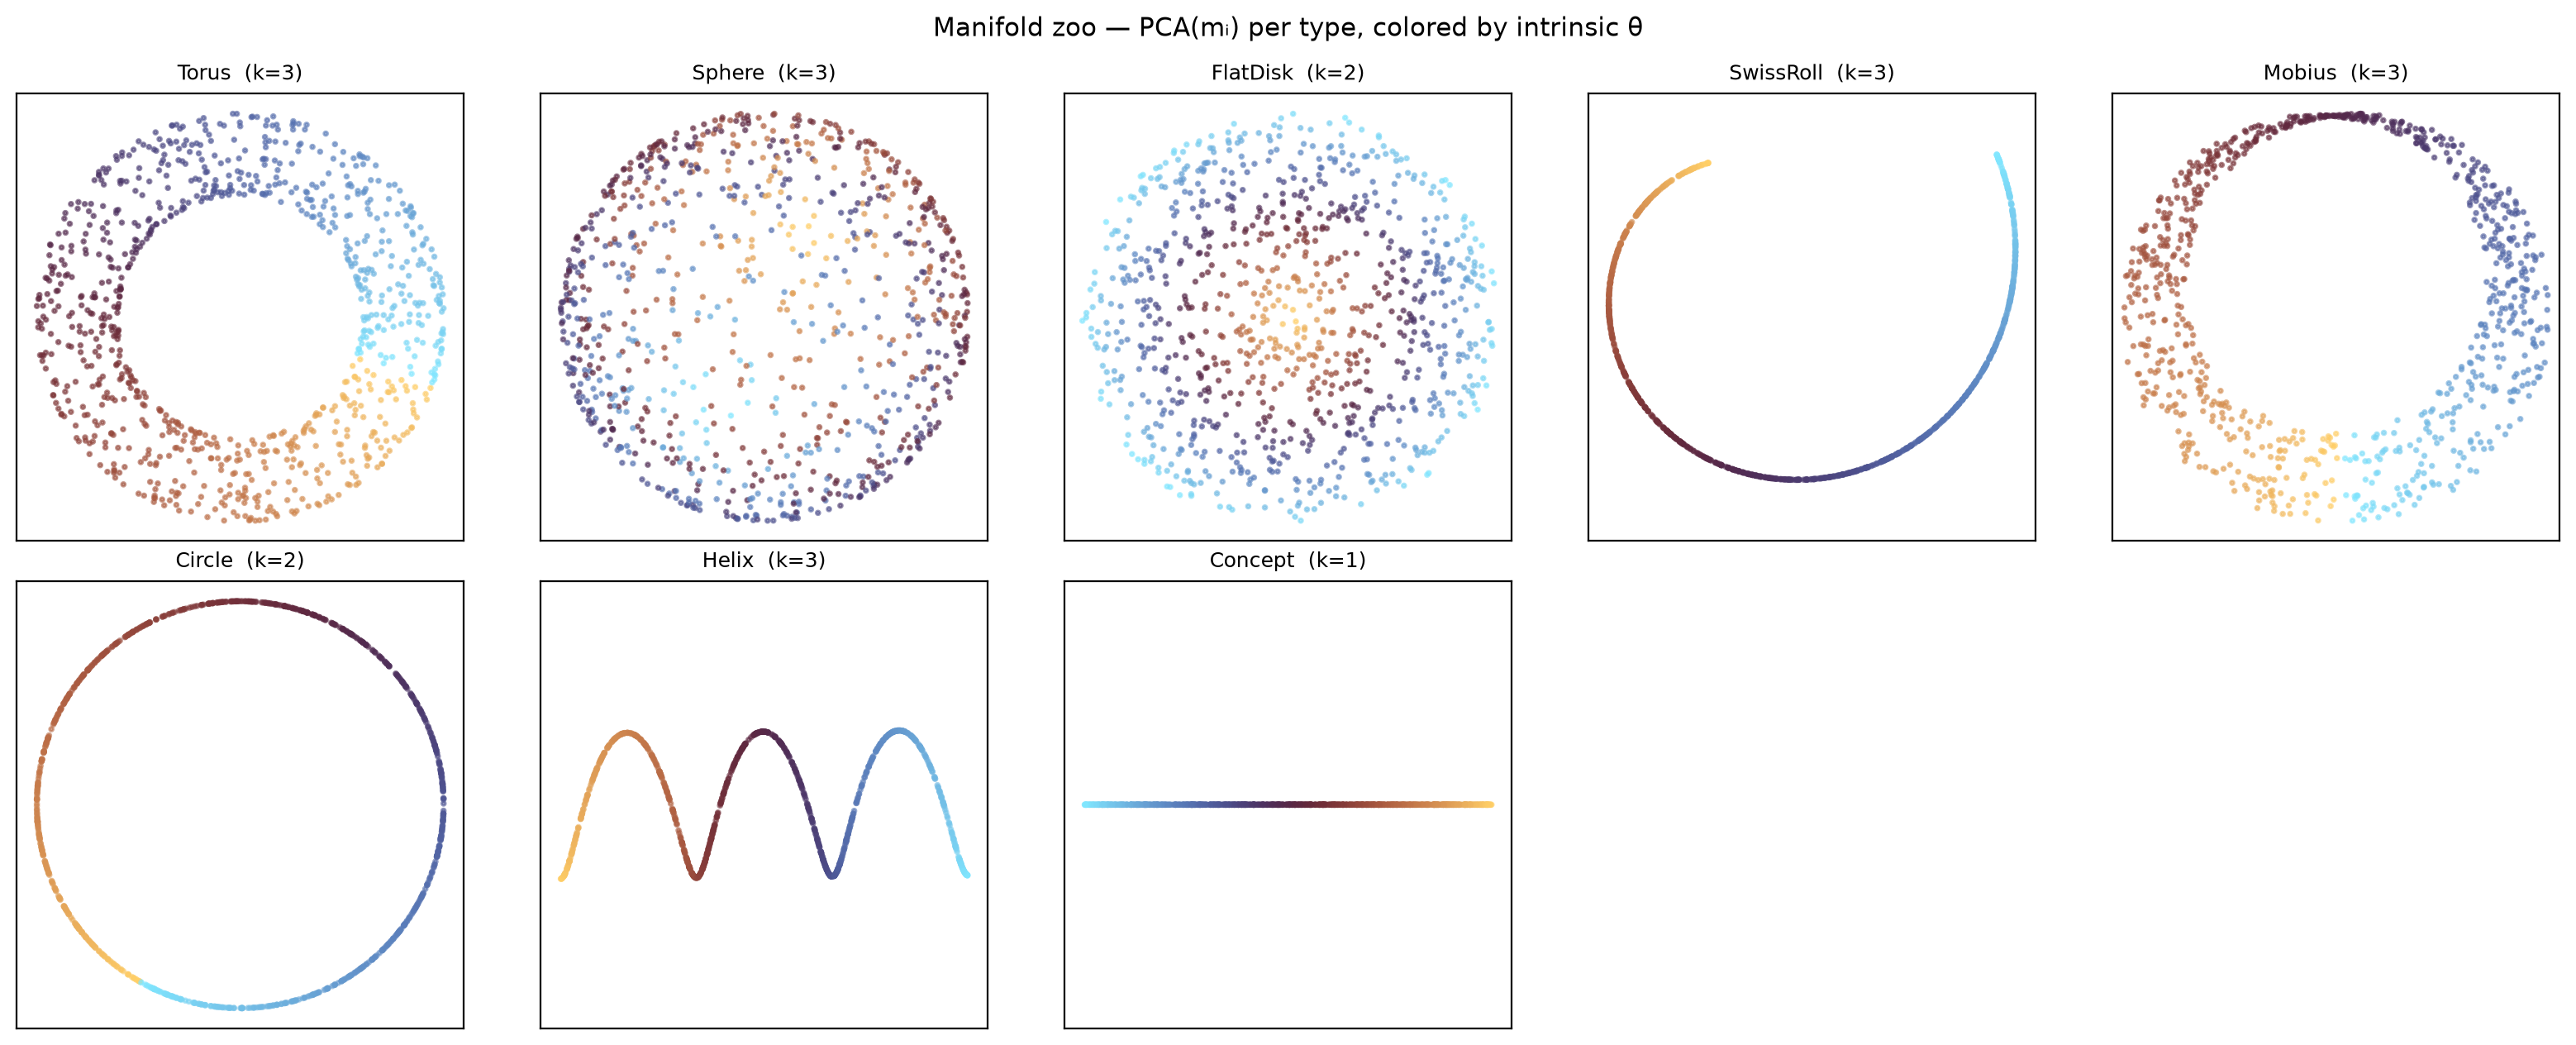

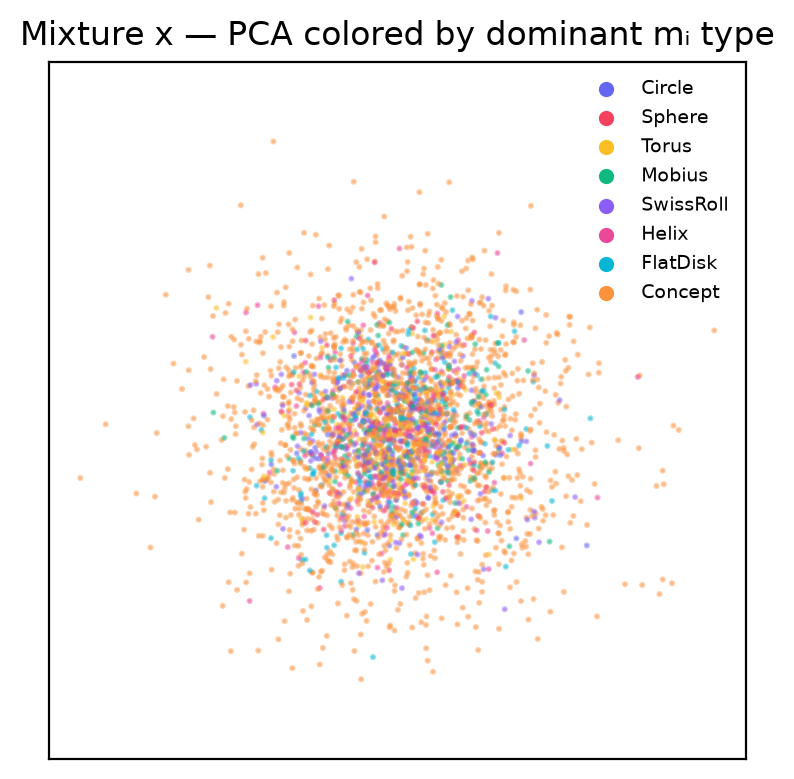

In [3]:
# 2-D PCA in numpy
def _pca2(X):
    X = X - X.mean(0)
    _, _, Vt = np.linalg.svd(X, full_matrices=False)
    return X @ Vt[:2].T

COLORS = {
    'Circle': '#6366f1', 'Sphere': '#f43f5e', 'Torus': '#fbbf24',
    'Mobius': '#10b981', 'SwissRoll': '#8b5cf6', 'Helix': '#ec4899',
    'FlatDisk': '#06b6d4', 'Concept': '#fb923c',
}

try:
    ZCMAP = plt.get_cmap('managua')       # preferred; fallback to viridis
except ValueError:
    ZCMAP = plt.get_cmap('viridis')

# One representative per manifold type
seen, reps = {}, []
for comp in dgp.components:
    if comp.mtype not in seen:
        seen[comp.mtype] = comp
        reps.append(comp)

ncols = min(len(reps), 5)
nrows = -(-len(reps) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.2, nrows * 3.2), squeeze=False)
axes = axes.flatten()

for ax, comp in zip(axes, reps):
    mask  = masks[:, comp.idx]
    mi    = m_te[mask, comp.idx]
    theta = test['thetas'][comp.idx][:, 0]
    t_norm = (theta - theta.min()) / (theta.max() - theta.min() + 1e-9)
    xy = _pca2(mi)
    ax.scatter(xy[:, 0], xy[:, 1], c=t_norm, cmap=ZCMAP, s=3, alpha=0.6, rasterized=True)
    ax.set_title(f'{comp.mtype}  (k={comp.ambient_dim})', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_box_aspect(1)                             # square panel
    ax.set_aspect('equal', adjustable='datalim')     # keep true shapes

for ax in axes[len(reps):]:
    ax.set_visible(False)

plt.suptitle('Manifold zoo — PCA(mᵢ) per type, colored by intrinsic θ', fontsize=11)
plt.tight_layout()
plt.show()

# Mixture: PCA of x colored by dominant mᵢ type
norms_dom = np.linalg.norm(m_te, axis=2)
norms_dom[~masks] = 0
dominant   = norms_dom.argmax(1)
dom_colors = [COLORS.get(dgp.components[i].mtype, '#888') for i in dominant]

xy_mix = _pca2(x_te[:3000])
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(xy_mix[:, 0], xy_mix[:, 1], c=dom_colors[:3000], s=1.5, alpha=0.4, rasterized=True)
for mtype, c in COLORS.items():
    ax.scatter([], [], c=c, s=20, label=mtype)
ax.legend(loc='upper right', fontsize=7, frameon=False)
ax.set_title('Mixture x — PCA colored by dominant mᵢ type')
ax.set_xticks([]); ax.set_yticks([])
ax.set_box_aspect(1)
ax.set_aspect('equal', adjustable='datalim')
plt.tight_layout()
plt.show()

## 3. Train the three models

In [4]:
# Classical SAE: ReLU + TopK, one atom per block (group_size=1), untied decoder.
# Width 4M atoms, k = l0 * group_size.
import torch.nn as nn
from toma.bsf.base import BSF, group_topk

class ClassicalSAE(BSF):
    def __init__(self, d, n_groups, l0=12):
        super().__init__(d, n_groups, group_size=1)
        self.l0 = l0
        W = torch.randn(n_groups, d); W = W / W.norm(dim=1, keepdim=True).clamp_min(1e-8)
        self.W_dec = nn.Parameter(W)
        self.W_enc = nn.Parameter(W.t().clone())   # tied init
        self.b_enc = nn.Parameter(torch.zeros(n_groups))
    def encode(self, x):
        a = torch.relu(x @ self.W_enc + self.b_enc).reshape(-1, self.n_groups, 1)
        return a * group_topk(a.norm(dim=-1), self.l0).unsqueeze(-1)
    def loss(self, x, target=None):
        target = x if target is None else target
        recon = (target - self(x)[0]).pow(2).mean()
        return recon, {'recon': recon.item()}

# name: (model, train kwargs). Grassmannian frames learn slowly at first, so lr=1e-3;
# n_groups=2.5M, per-block gamma and 15% input noise help it.
M = cfg.n_components
MODELS = {
    'Block BSF':        (bsf.VanillaBSF(d=cfg.d, n_groups=2 * M, group_size=3, l0=cfg.l0),
                         dict(epochs=60, lr=4e-4, snr=0.1)),
    'Grassmannian BSF': (bsf.GrassmannianBSF(d=cfg.d, n_groups=round(2.5 * M), group_size=3, l0=cfg.l0),
                         dict(epochs=100, lr=1e-3, snr=0.15)),
    'Classical SAE':    (ClassicalSAE(d=cfg.d, n_groups=cfg.sae_width, l0=cfg.sae_k),
                         dict(epochs=60, lr=4e-4, snr=0.1)),
}
for name, (model, kw) in MODELS.items():
    print(f'--- {name}')
    bsf.train(model, x_tr, device=DEVICE, **kw)

--- Block BSF


epoch   1/60   loss=0.0047   R2=0.5724   L0=4.0   dead=1/256


epoch   5/60   loss=0.0008   R2=0.9061   L0=4.0   dead=7/256


epoch  10/60   loss=0.0005   R2=0.9438   L0=4.0   dead=58/256


epoch  15/60   loss=0.0004   R2=0.9514   L0=4.0   dead=110/256


epoch  20/60   loss=0.0004   R2=0.9528   L0=4.0   dead=122/256


... (40 outputs left out)

epoch  45/60   loss=0.0003   R2=0.9618   L0=11.5   dead=10/512


epoch  50/60   loss=0.0003   R2=0.9619   L0=11.5   dead=8/512


epoch  55/60   loss=0.0003   R2=0.9618   L0=11.6   dead=8/512


epoch  60/60   loss=0.0003   R2=0.9622   L0=11.6   dead=6/512


## 4. Recovery scores

In [5]:
# Block models: match each concept to the group that best predicts when it is active
# (group F1), then reconstruct mᵢ from that group's atoms only (group-oracle R²).
# SAE: F1 of the single best atom; R² from the sample's top-k_i atoms (k_i = ambient dim).
x_te_t = torch.as_tensor(x_te, dtype=torch.float32, device=DEVICE)
RES = {}
for name, (model, _) in MODELS.items():
    with torch.no_grad():
        z = model.encode(x_te_t)
    codes = z.reshape(z.shape[0], -1).cpu().numpy()           # (N, G*K)
    dictionary = model.decoder_atoms().detach().cpu().numpy()  # (G*K, d)
    if model.group_size > 1:
        best_g, f1 = best_group_per_component(codes, model.n_groups, model.group_size, masks, dgp.components)
        r2 = group_oracle_r2(codes, dictionary, model.group_size, m_te, masks, dgp.components, best_groups=best_g)
    else:
        best_g = None
        f1, _ = component_f1(codes, masks, dgp.components)
        r2 = oracle_k_r2(codes, dictionary, m_te, masks, dgp.components)
    RES[name] = dict(model=model, codes=codes, dictionary=dictionary, best_g=best_g,
                     r2=r2, f1=f1, r2_recon=bsf.recon_r2(model, x_te_t))

print(f'{"model":<18}{"recon R²":>10}{"concept R²":>12}{"concept F1":>12}')
for name, r in RES.items():
    print(f'{name:<18}{r["r2_recon"]:>10.4f}{np.nanmean(r["r2"]):>12.4f}{np.nanmean(r["f1"]):>12.4f}')

model               recon R²  concept R²  concept F1
Block BSF             0.9561      0.9253      0.8419
Grassmannian BSF      0.9134      0.8583      0.8166
Classical SAE         0.9613     -0.9249      0.5054


## 5. Per-concept recovery

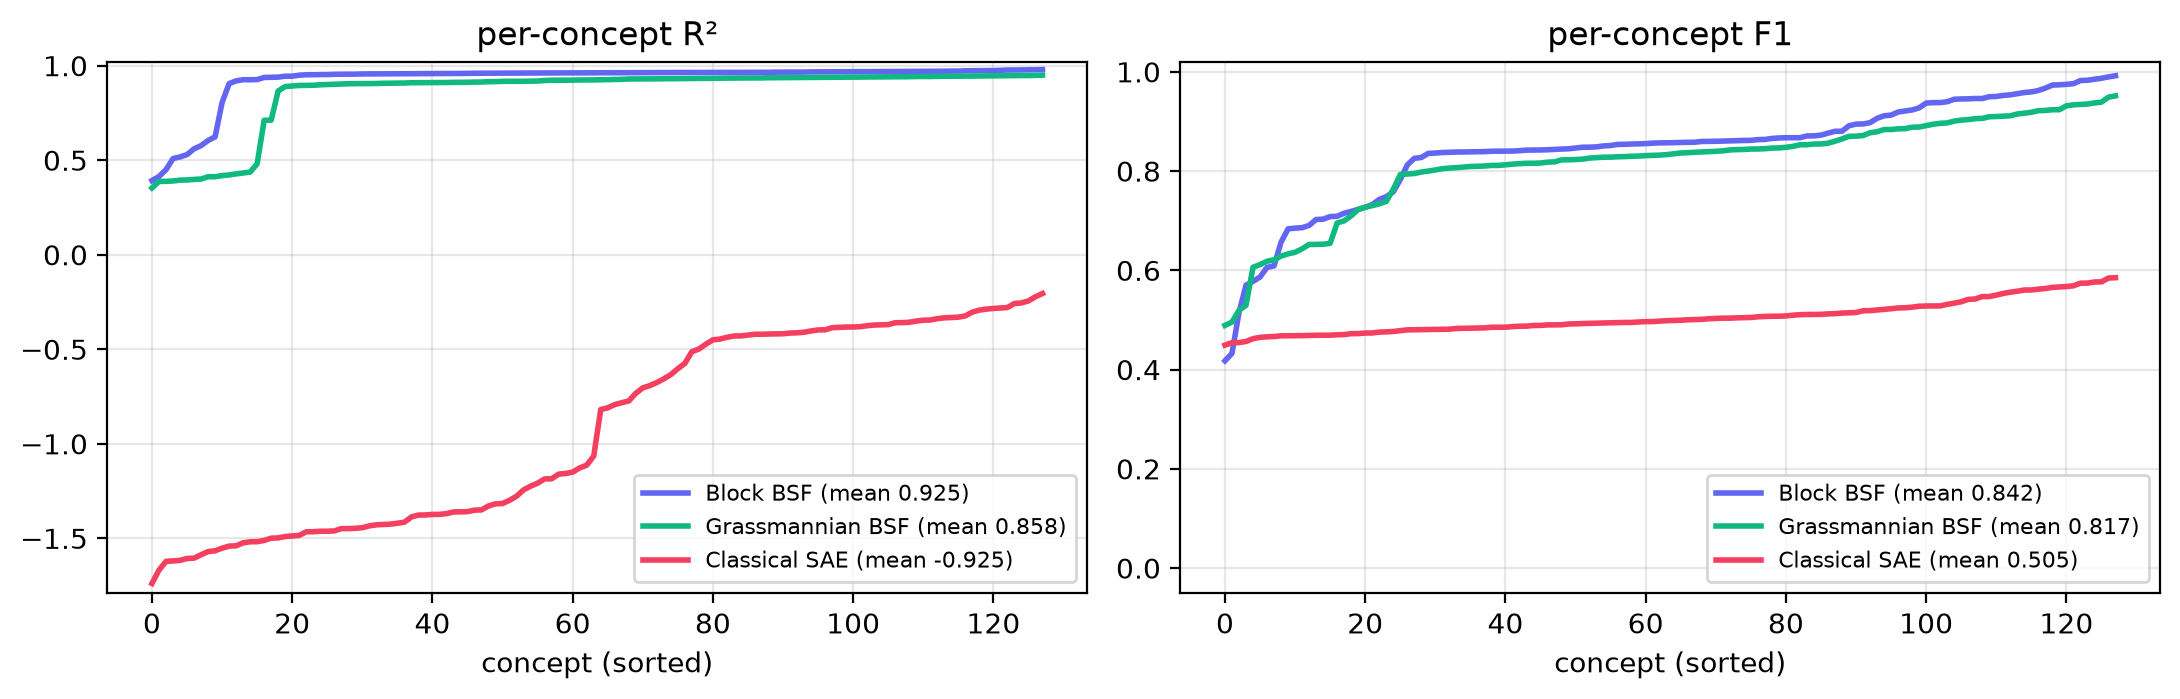

In [6]:
# Per-concept R² and F1, sorted, one line per model.
MODEL_COLORS = {'Block BSF': '#6366f1', 'Grassmannian BSF': '#10b981', 'Classical SAE': '#f43f5e'}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, key, title in [(ax[0], 'r2', 'per-concept R²'), (ax[1], 'f1', 'per-concept F1')]:
    lo = 0.0
    for name, r in RES.items():
        vals = np.sort(r[key][~np.isnan(r[key])])
        a.plot(vals, lw=2, color=MODEL_COLORS[name], label=f'{name} (mean {vals.mean():.3f})')
        lo = min(lo, float(vals.min()))
    a.set_title(title); a.set_xlabel('concept (sorted)')
    a.set_ylim(lo - 0.05, 1.02)
    a.legend(loc='lower right', fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. True vs recovered manifolds in 3D

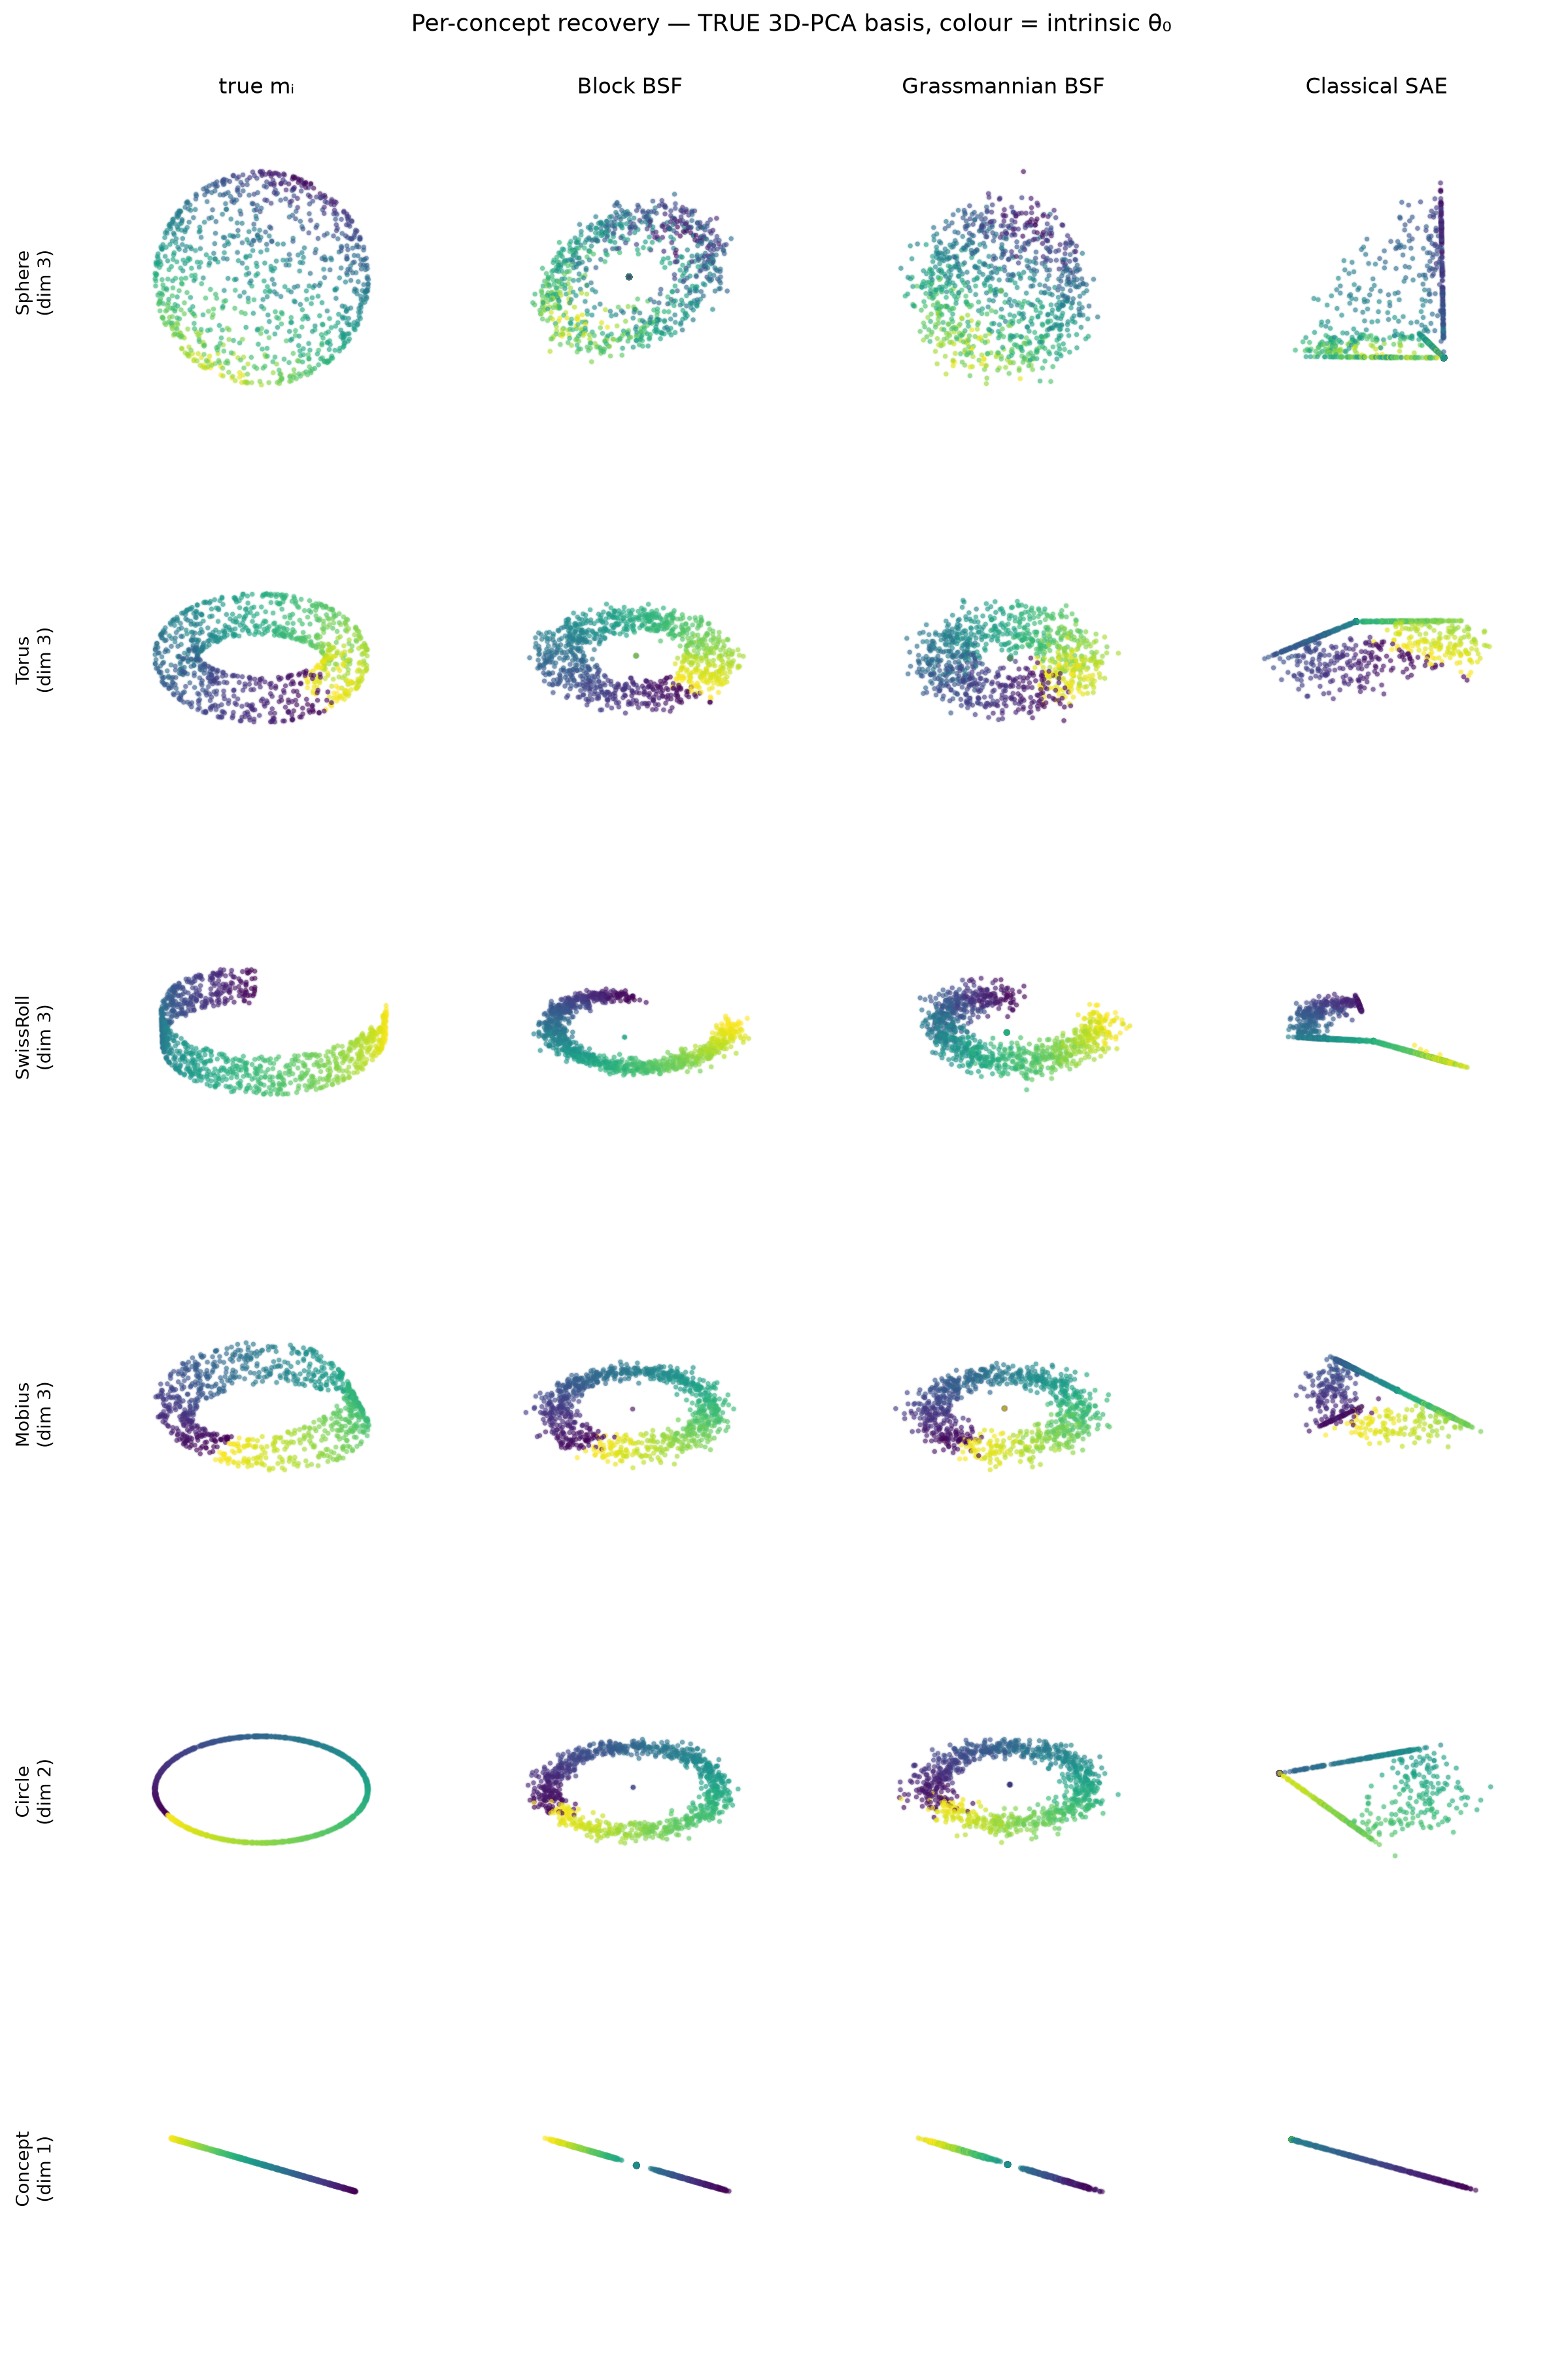

In [7]:
CMAP = plt.get_cmap('viridis')

def style_panel(ax, p, col, cmap, s=7.0, core_alpha=0.6):
    'Translucent halo under a translucent core.'
    p = p - p.mean(0)
    ax.computed_zorder = False
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=col, cmap=cmap, s=s * 2.0,
               alpha=0.1, linewidths=0, depthshade=False, zorder=1)   # halo
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=col, cmap=cmap, s=s,
               alpha=core_alpha, linewidths=0, depthshade=False, zorder=2)   # core
    # Equal data limits on all 3 axes so shapes are not distorted.
    c = (p.max(0) + p.min(0)) / 2; R = np.ptp(p, axis=0).max() / 2 + 1e-9
    ax.set_xlim(c[0] - R, c[0] + R); ax.set_ylim(c[1] - R, c[1] + R); ax.set_zlim(c[2] - R, c[2] + R)
    ax.set_axis_off()
    ax.set_aspect('equal')

# Atoms used to reconstruct concept i: its matched group (block models)
# or its k best atoms (SAE, group_size=1).
def unit_atoms(r, i, k):
    gs = r['model'].group_size
    if gs > 1:
        return np.arange(r['best_g'][i] * gs, (r['best_g'][i] + 1) * gs)
    absc = np.abs(r['codes'])
    return np.argsort(absc[masks[:, i]].mean(0) - absc[~masks[:, i]].mean(0))[-k:]

# One example per manifold type: curved first, then a Concept
WANT = ['Sphere', 'Torus', 'SwissRoll', 'Mobius', 'Circle', 'Concept']
chosen = []
for want in WANT:
    for comp in dgp.components:
        if comp.mtype == want and masks[:, comp.idx].sum() > 200:
            chosen.append(comp); break

ncol = 1 + len(RES)
fig = plt.figure(figsize=(3.0 * ncol, len(chosen) * 3.0))
for row, comp in enumerate(chosen):
    i = comp.idx
    act = np.flatnonzero(masks[:, i])
    m_true = m_te[act, i].astype(np.float64); mu = m_true.mean(0)
    _, _, Vt = np.linalg.svd(m_true - mu, full_matrices=False); V = Vt[:3]   # true basis
    th  = test['thetas'][i]
    col = th[:, 0] if th is not None and th.size else np.zeros(len(act))
    panels = [('true mᵢ', m_true)]
    for name, r in RES.items():
        atoms = unit_atoms(r, i, comp.ambient_dim)
        panels.append((name, r['codes'][act][:, atoms] @ r['dictionary'][atoms]))
    for c, (name, pts) in enumerate(panels):
        ax = fig.add_subplot(len(chosen), ncol, row * ncol + c + 1, projection='3d')
        style_panel(ax, (pts - mu) @ V.T, col, CMAP)     # all in the true basis
        if row == 0: ax.set_title(name, fontsize=12)
        if c == 0:
            ax.text2D(-0.12, 0.5, f'{comp.mtype}\n(dim {comp.ambient_dim})',
                      transform=ax.transAxes, fontsize=10, rotation=90, va='center', ha='center')
fig.suptitle('Per-concept recovery — TRUE 3D-PCA basis, colour = intrinsic θ₀', fontsize=13, y=1.0)
fig.tight_layout(); plt.show()